In [1]:
#importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [5]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [7]:
print("All libraries imported successfully")

All libraries imported successfully


In [11]:
df = pd.read_csv("score.csv")
df

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30
5,1.5,20
6,9.2,88
7,5.5,60
8,8.3,81
9,2.7,25


In [12]:
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [13]:
df.tail()

,Hours,Scores
20,2.7,30
21,4.8,54
22,3.8,35
23,6.9,76
24,7.8,86


In [14]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
Hours,2.5,5.1,3.2,8.5,3.5,1.5,9.2,5.5,8.3,2.7,...,8.9,2.5,1.9,6.1,7.4,2.7,4.8,3.8,6.9,7.8
Scores,21.0,47.0,27.0,75.0,30.0,20.0,88.0,60.0,81.0,25.0,...,95.0,30.0,24.0,67.0,69.0,30.0,54.0,35.0,76.0,86.0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes


In [17]:
df.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [19]:
df.columns

Index(['Hours', 'Scores'], dtype='object')

In [20]:
df.columns.values

array(['Hours', 'Scores'], dtype=object)

In [21]:
df.dtypes

,0
Hours,float64
Scores,int64


In [23]:
df.Hours

,Hours
0,2.5
1,5.1
2,3.2
3,8.5
4,3.5
5,1.5
6,9.2
7,5.5
8,8.3
9,2.7


In [36]:
#EDA [exploratory data analysis]

print("dataset shape")
df.shape


dataset shape


(25, 2)

In [33]:
print("number of rows")
df.shape[0]

number of rows


25

In [34]:
print("number of columns")
df.shape[1]

number of columns


2

In [38]:
#MISSING VALUES

df.isnull().sum()

,0
Hours,0
Scores,0


In [39]:
#DUPLICATE VALUES

df.duplicated().sum()

np.int64(0)

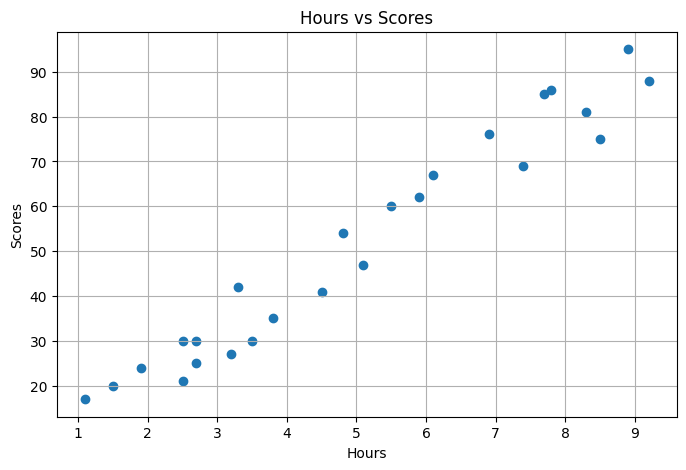

In [46]:
#data visualization

plt.figure(figsize=(8,5))
plt.scatter(df['Hours'], df['Scores']
)

plt.title("Hours vs Scores")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.grid(True)

plt.show()

In [48]:
#CORRELATION

correlation = df['Hours'].corr(df['Scores'])
correlation

np.float64(0.9761906560220887)

In [51]:
#DATA PREPARATION

#independent var
X = df[['Hours']]

#dependent var
y = df['Scores']

In [52]:
print("independent var")
X

independent var


,Hours
0,2.5
1,5.1
2,3.2
3,8.5
4,3.5
5,1.5
6,9.2
7,5.5
8,8.3
9,2.7


In [53]:
print("dependent var")
y

dependent var


,Scores
0,21
1,47
2,27
3,75
4,30
5,20
6,88
7,60
8,81
9,25


In [54]:
#TRAIN & TEST split data

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [55]:
print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training Data: (20, 1)
Testing Data: (5, 1)
Training Target: (20,)
Testing Target: (5,)


In [57]:
#BUILD AND CREATE MODEL

model = LinearRegression()
print("Linear regression model created successfully")

Linear regression model created successfully


In [60]:
#Train the model

model.fit(X_train,y_train)
print("model trained successfully")

model trained successfully


In [63]:
model.coef_[0]

np.float64(9.682078154455697)

In [64]:
model.intercept_

np.float64(2.826892353899737)

In [71]:
#Prediction using testing values

y_pred = model.predict(X_test)
print("actual values")
y_test.values
y_test

actual values


,Scores
8,81
16,30
0,21
23,76
11,62


In [69]:
print("predicted values")
y_pred

predicted values


array([83.18814104, 27.03208774, 27.03208774, 69.63323162, 59.95115347])

In [72]:
#COMPARISION

comparison = pd.DataFrame({
    'Actual Scores': y_test.values,
    'Predicted Scores': y_pred
})

print(comparison)

   Actual Scores  Predicted Scores
0             81         83.188141
1             30         27.032088
2             21         27.032088
3             76         69.633232
4             62         59.951153


In [75]:
#MODEL EVALUATION USING METRICS

mae = mean_absolute_error(y_test,y_pred)
print('mae:',mae)

mae: 3.9207511902099244


In [76]:
mse = mean_squared_error(y_test,y_pred)
print('mse:',mse)

mse: 18.943211722315272


In [78]:
rmse = np.sqrt(mse)
print('rmse:',rmse)

rmse: 4.352380006653288


In [77]:
r2_score = r2_score(y_test,y_pred)
print('r2_score:',r2_score)


r2_score: 0.9678055545167994


In [81]:
print(" MODEL PERFORMANCE")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2_score)

 MODEL PERFORMANCE
MAE: 3.9207511902099244
MSE: 18.943211722315272
RMSE: 4.352380006653288
R2 Score: 0.9678055545167994


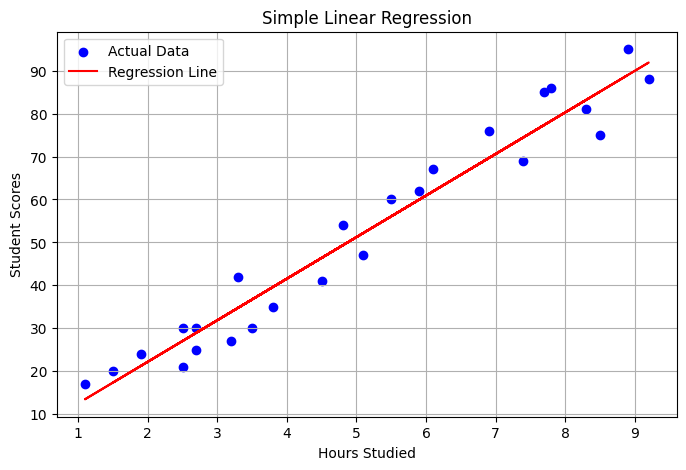

In [82]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X,
    y,
    color='blue',
    label='Actual Data'
)

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.title("Simple Linear Regression")

plt.xlabel("Hours Studied")

plt.ylabel("Student Scores")

plt.legend()

plt.grid(True)

plt.show()

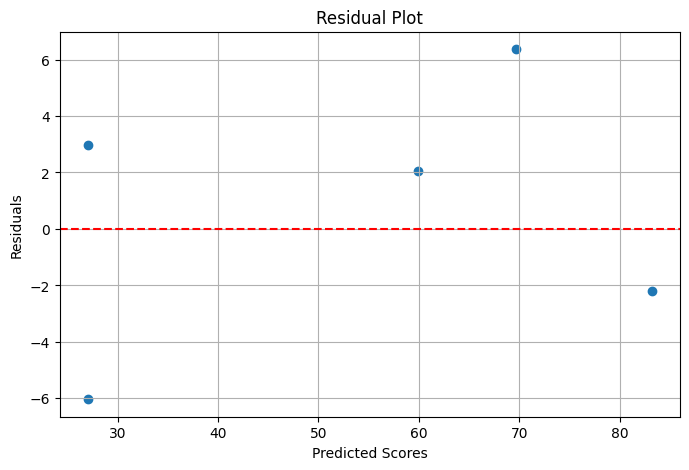

In [83]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.title("Residual Plot")

plt.xlabel("Predicted Scores")

plt.ylabel("Residuals")

plt.grid(True)

plt.show()

In [84]:
new_student = pd.DataFrame({
    'Hours': [9.5]
})

predicted_score = model.predict(new_student)

print("Study Hours:", 9.5)

print("Predicted Student Score:", predicted_score[0])

Study Hours: 9.5
Predicted Student Score: 94.80663482122885
